number of loaded training images:  555
loaded 70 training batches.
number of loaded val images:  186
loaded 24 validation batches.
data_batch.size= torch.Size([8, 1, 256, 256])

epoch  1  started!  LR= [0.0001]
train_loss:  0.50554960668087
val_loss:  0.49370190625389415
Validation_Dice Score = 0.337996542454
The best model saved...
Best validation dice= 0.33799654245376587  in epoch  1
Epoch finished in 6.278357058065012 seconds.


epoch  2  started!  LR= [0.0001]
train_loss:  0.3364888425384249
val_loss:  0.27357997248570126
Validation_Dice Score = 0.018381206319
Best validation dice= 0.33799654245376587  in epoch  1
Epoch finished in 2.056343583855778 seconds.


epoch  3  started!  LR= [0.0001]
train_loss:  0.25223520398139954
val_loss:  0.19809017268319926
Validation_Dice Score = 0.023125436157
Best validation dice= 0.33799654245376587  in epoch  1
Epoch finished in 2.022782971849665 seconds.


epoch  4  started!  LR= [0.0001]
train_loss:  0.2057918893439429
val_loss:  0.2104208872

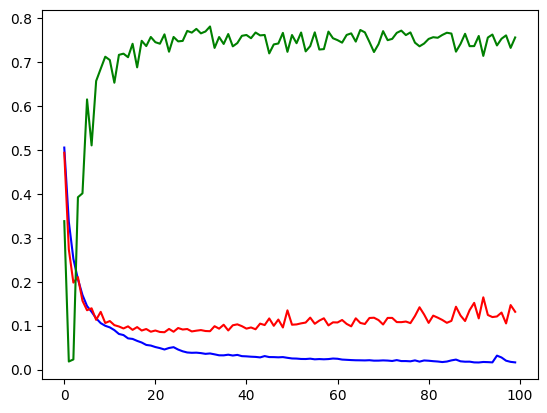

number of loaded test images:  186
loaded 24 test batches.
test Dice Score = 0.764388680458


In [2]:
ROOT = '/home/jupyter-r.yazdi/myproject/dti3d/0pycodes/UnetMaxsig/BUSI_WHU/'
config = {
    "lr": 1e-4,
    "batch_size": 8,
    "epochs": 100,
    "segformer_variant": "b0",  # b0 (smallest/fastest) ... b5 (largest); see SegFormerBinary
    }

# %%
from time import perf_counter
import numpy as np
import cv2
import matplotlib.pyplot as plt

import os
from glob import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torchvision import transforms
import torchvision.transforms.functional as TF
from torchvision.utils import make_grid
from PIL import Image

from torch.optim.lr_scheduler import StepLR
from torch.utils.data import DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

from transformers import SegformerConfig, SegformerForSemanticSegmentation

# %%
#dataset
# Training from scratch, so no pretrained encoder to match -> we keep the
# image as single-channel grayscale, same as the UNet version. Mask handling
# is unchanged.
from torch.utils.data import Dataset
class mydataset(Dataset):
    def __init__(self,images_dir,masks_dir,transforms_img=None):
        self.images_dir=images_dir
        self.masks_dir=masks_dir
        self.transforms_img=transforms_img
        self.mask_names= glob(masks_dir + "*.bmp")

    def __len__(self):
        return len(self.mask_names)

    def __getitem__(self,index):
        mask_name=self.mask_names[index]
        mask=cv2.imread(mask_name,cv2.IMREAD_ANYDEPTH)
        mask = (mask - mask.min()) / (mask.max() - mask.min())#ejbari
        mask= (mask>0).astype(np.float32)
        mask = cv2.resize(mask, (256, 256), interpolation=cv2.INTER_AREA)

        imgn=mask_name.replace('/masks/','/images/').replace('_anno.bmp','.bmp')

        image=cv2.imread(imgn,cv2.IMREAD_ANYDEPTH)
        image = (image - image.min()) / (image.max() - image.min()).astype(np.float32)#ejbari
        image = cv2.resize(image, (256, 256), interpolation=cv2.INTER_AREA)

        if self.transforms_img is not None:
            transformed = self.transforms_img(image=image, mask=mask)
            image = transformed["image"]
            mask = transformed["mask"]

        return image, mask

# %%
#train dataset

images_dir= ROOT + 'dataset/train/images/'
masks_dir= ROOT + 'dataset/train/masks/'
batch_size=config['batch_size']
shuffle=True

train_transform = A.Compose([

    #A.RandomCrop(256,256,always_apply=True, p=1.0),
    #A.UnsharpMask (blur_limit=(3, 5), sigma_limit=0, alpha=(0.2, 0.5), threshold=10, always_apply=False, p=0.1),
    #A.RandomGamma (gamma_limit=(80, 150), always_apply=False, p=0.1),
    #A.RandomBrightnessContrast (brightness_limit=0.2, contrast_limit=0.5, brightness_by_max=True, always_apply=False, p=0.25),
    #A.PadIfNeeded (min_height=1048, min_width=790, border_mode=cv2.BORDER_CONSTANT, value=0,always_apply=True, p=1.0),

    #A.Resize(256,256),
    ToTensorV2()])


train_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=train_transform)
print("number of loaded training images: ",train_ds.__len__())

train_dataset = DataLoader(train_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(train_dataset), "training batches.")

# %%
#val dataset

images_dir= ROOT + 'dataset/val/images/'
masks_dir= ROOT + 'dataset/val/masks/'
batch_size=config['batch_size']
shuffle=True

val_transform = A.Compose([

    #A.PadIfNeeded (min_height=790, min_width=790, border_mode=cv2.BORDER_CONSTANT, value=0,always_apply=True,  p=1.0),
    #A.Resize(256,256),
    ToTensorV2()])

val_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=val_transform)
print("number of loaded val images: ",val_ds.__len__())

val_dataset = DataLoader(val_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(val_dataset), "validation batches.")

# %%
# ---- SegFormer model wrapper (trained from scratch, no pretrained weights) ----
# SegformerConfig() alone defines an architecture equivalent to the b0 variant
# (depths=[2,2,2,2], hidden_sizes=[32,64,160,256], decoder_hidden_size=256).
# Passing a config (instead of calling .from_pretrained) gives a fresh,
# randomly-initialized model - no internet download, no pretrained weights.
# num_channels=1 matches your grayscale input directly (no need to fake RGB
# since there's no pretrained RGB encoder to match anymore).
# num_labels=1 keeps a single foreground logit so we can reuse
# BCEWithLogitsLoss + sigmoid exactly like the UNet version.
# SegformerForSemanticSegmentation outputs logits at 1/4 input resolution
# (e.g. 256x256 input -> 64x64 logits), so we upsample back to the mask size.
class SegFormerBinary(nn.Module):
    def __init__(self, out_size=(256, 256), variant="b1"):
        super().__init__()

        # architecture presets from the SegFormer paper (encoder only differs
        # in depths / hidden_sizes; decoder head size also scales for b4/b5)
        variants = {
            "b0": dict(depths=[2, 2, 2, 2],  hidden_sizes=[32, 64, 160, 256],  decoder_hidden_size=256),
            "b1": dict(depths=[2, 2, 2, 2],  hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=256),
            "b2": dict(depths=[3, 4, 6, 3],  hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
            "b3": dict(depths=[3, 4, 18, 3], hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
            "b4": dict(depths=[3, 8, 27, 3], hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
            "b5": dict(depths=[3, 6, 40, 3], hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
        }
        preset = variants[variant]

        seg_config = SegformerConfig(
            num_channels=1,
            num_labels=1,
            depths=preset["depths"],
            hidden_sizes=preset["hidden_sizes"],
            decoder_hidden_size=preset["decoder_hidden_size"],
        )
        self.model = SegformerForSemanticSegmentation(seg_config)
        self.out_size = out_size

    def forward(self, x):
        logits = self.model(pixel_values=x).logits  # [B, 1, H/4, W/4]
        logits = F.interpolate(logits, size=self.out_size, mode="bilinear", align_corners=False)
        return logits


# %%
torch.manual_seed(42)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

data_batch,mask_name = next(iter(train_dataset))
print("data_batch.size=",data_batch.size())

model=SegFormerBinary(variant=config['segformer_variant']).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model.parameters(),lr=config['lr'])

scheduler = StepLR(optimizer, step_size=100, gamma=0.83)
scaler = torch.amp.GradScaler('cuda')

best_valid_dice=0
best_epoch=0
train_loss_plot=[]
val_loss_plot=[]
val_dice_plot=[]
last_lr=scheduler.get_last_lr()

for epoch in range(config['epochs']):

    if(last_lr != scheduler.get_last_lr()):
        print(80*'-')
        print(f'The lr changed from {last_lr} to {scheduler.get_last_lr()}. thus previous best model loaded!')
        last_lr = scheduler.get_last_lr()

    print("\r\nepoch ",epoch+1," started!",' LR=', last_lr)

    t_start = perf_counter()

    #model training step
    running_loss = 0.0
    model.train()
    for inputs,mask in train_dataset:

        optimizer.zero_grad()
        with torch.autocast(device_type="cuda"):
            outputs = model(inputs.to(device))
            labels=mask.to(device).unsqueeze(1)
            loss = criterion(outputs, labels)

        running_loss += loss.item()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

    ep_loss=running_loss / len(train_dataset)
    print("train_loss: " ,ep_loss)
    train_loss_plot.append(ep_loss)
    scheduler.step()

    #model evaluation step
    dice_score = 0
    val_loss = 0.0
    with torch.no_grad():
        model.eval()
        for inputs,mask in val_dataset:

            inputs=inputs.to(device)
            preds =model(inputs)
            labels=mask.to(device).unsqueeze(1)
            loss = criterion(preds, labels)
            val_loss += loss.item()

            pred_sig=torch.sigmoid(preds)

            preds=(pred_sig>0.5).float()
            intersection=(preds * labels).sum()
            union=(preds + labels).sum()
            dice_score += (2 * intersection / union)

    ep_loss=val_loss / len(val_dataset)
    print("val_loss: " ,ep_loss)
    val_loss_plot.append(ep_loss)
    epoch_dc= float(dice_score/len(val_dataset))
    val_dice_plot.append(epoch_dc)
    print(f"Validation_Dice Score = {epoch_dc:.12f}")
    if(best_valid_dice< epoch_dc):
        best_valid_dice=epoch_dc
        best_epoch=epoch
        torch.save(model.state_dict(), 'best-model-segformer.pt')
        print('The best model saved...')

    print('Best validation dice=',best_valid_dice, ' in epoch ', best_epoch+1)
    print(f"Epoch finished in {perf_counter()-t_start} seconds.\r\n")


# %%
plt.plot(train_loss_plot, color='blue',label='train_loss')
plt.plot(val_loss_plot, color='red',label='val_loss')
plt.plot(val_dice_plot ,color='green',label='val_dice')
plt.show()

# %%
#test dataset

images_dir= ROOT + 'dataset/test/images/'
masks_dir= ROOT + 'dataset/test/masks/'
batch_size=config['batch_size']
shuffle=True

test_transform = A.Compose([
    ToTensorV2()])

test_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=test_transform)
print("number of loaded test images: ",test_ds.__len__())

test_dataset = DataLoader(test_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(test_dataset), "test batches.")

# %%
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---- Binary semantic segmentation example ----
model=SegFormerBinary(variant=config['segformer_variant']).to(device)
#model evaluation step
dice_score = 0
model.load_state_dict(torch.load('best-model-segformer.pt'))
with torch.no_grad():
    model.eval()
    for inputs,mask in test_dataset:

        inputs=inputs.to(device)
        preds =model(inputs)
        labels=mask.to(device).unsqueeze(1)
        pred_sig=torch.sigmoid(preds)
        preds=(pred_sig>0.5).float()
        intersection=(preds * labels).sum()
        union=(preds + labels).sum()
        dice_score += (2 * intersection / union)

epoch_dc= float(dice_score/len(test_dataset))

print(f"test Dice Score = {epoch_dc:.12f}")
